In [6]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm
import scipy


The basics physical parameters of a linear RLC circuit:

L: the unduction factor of the ideal coil

R: the resostance of the ideal resistor

C: the capacitance of the ideal capacitor


The driving voltage of the system V(t) = Vocos(ωt)

Vo: The amplitude of the driving voltage

ω: angular frequency of the system


For evalaute the equations we need the proper time parameters:

t_start

t_end

dt

The second order homogeneous liner ODE:


L*(d^2q)/(dt^2) + R(dq/dt)+ 1/C*q = V(t)

The 2 first order homogeneous liner ODEs:

I = dq/dt

L*(dI/dt) + R*I + 1/C*q = V(t) = Vo*cos(ωt) => dI/dt = 1/L * (Vo*cos(ωt) - RI- 1/C q)



In [7]:
#Time parameters
t_start = 0.0
t_end = 20.0
dt = 0.01

time = np.arange(t_start, t_end, dt)

In [8]:
#Parameters
L = 1.0
R = 1.0
C = 1.0
Vo = 1.0
omega = 1.0


In [9]:
#physics function for linear RLC circuit
def lin_RLC_der(t, q, I):
    V_t = Vo * np.cos(omega * t)
    dqdt = I
    dIdt = (V_t - R * I - q / C) / L
    return dqdt, dIdt


EULER METHOD

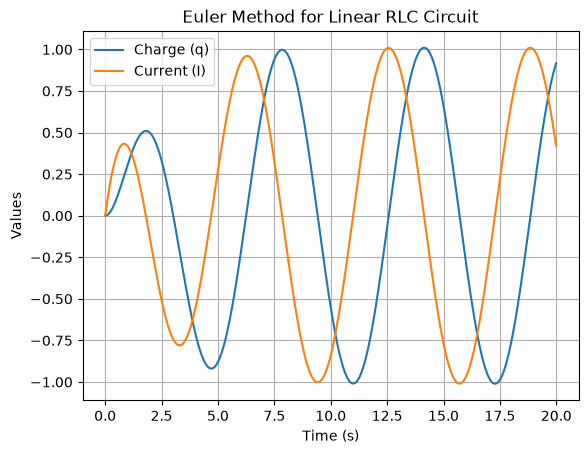

In [10]:
#Two arrays to store the results of the Euler method
q_Euler = np.zeros(len(time))
I_Euler = np.zeros(len(time))

#Initial conditions
q_Euler[0] = 0.0
I_Euler[0] = 0.0


for i in range(1, len(time)):
    dqdt, dIdt = lin_RLC_der(time[i-1], q_Euler[i-1], I_Euler[i-1]) #pass the previous values to the function
    q_Euler[i] = q_Euler[i-1] + dqdt * dt #unpack the returned values and update the arrays
    I_Euler[i] = I_Euler[i-1] + dIdt * dt #new = old + derivative * dt


plt.plot(time, q_Euler, label='Charge (q)')
plt.plot(time, I_Euler, label='Current (I)')
plt.xlabel('Time (s)')
plt.ylabel('Values')
plt.title('Euler Method for Linear RLC Circuit')
plt.legend()
plt.grid()
plt.show()

4TH-ORDER RUNGE-KUTTA (RK4)

In [ ]:
k1q, k1I = lin_RLC_der(time[0], q_Euler[0], I_Euler[0])